In [ ]:
#  Імпорт необхідних бібліотек

# Основні бібліотеки для YOLO
from ultralytics import YOLO
import torch

# Перевірка доступності GPU
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")
    print(f"GPU device: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

# Бібліотеки для аналізу та візуалізації
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import cv2
import os
from pathlib import Path

# Налаштування відображення графіків
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("\n✓ Всі бібліотеки успішно імпортовано!")


PyTorch version: 2.14.0+cu126
CUDA available: True
CUDA version: 12.6
GPU device: NVIDIA GeForce GTX 1070 Ti
GPU memory: 8.00 GB

✓ Всі бібліотеки успішно імпортовано!


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
YOLO_DATA_DIR = DATA_DIR / "indoor_objects_yolo"

MODELS_DIR = PROJECT_DIR / "models"
RUNS_DIR = PROJECT_DIR / "runs"
REPORTS_DIR = PROJECT_DIR / "reports"

for folder in [
    DATA_DIR,
    RAW_DATA_DIR,
    YOLO_DATA_DIR,
    MODELS_DIR,
    RUNS_DIR,
    REPORTS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Поточна папка проєкту:", PROJECT_DIR)
print("\nСтворені/наявні папки:")
for folder in [RAW_DATA_DIR, YOLO_DATA_DIR, MODELS_DIR, RUNS_DIR, REPORTS_DIR]:
    print("✓", folder)

Поточна папка проєкту: g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08

Створені/наявні папки:
✓ g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\raw
✓ g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo
✓ g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\models
✓ g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\runs
✓ g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\reports


In [3]:
import sys

!"{sys.executable}" -m pip install -U kaggle


   --- ------------------------------------  1/11 [tqdm]
   -------------- -------------------------  4/11 [protobuf]
   -------------- -------------------------  4/11 [protobuf]
   --------------------- ------------------  6/11 [markdown-it-py]
   --------------------- ------------------  6/11 [markdown-it-py]
   --------------------- ------------------  6/11 [markdown-it-py]
   ------------------------- --------------  7/11 [kagglesdk]
   ------------------------- --------------  7/11 [kagglesdk]
   ------------------------- --------------  7/11 [kagglesdk]
   ------------------------- --------------  7/11 [kagglesdk]
   ----------------------------- ----------  8/11 [mdit-py-plugins]
   -------------------------------- -------  9/11 [jupytext]
   -------------------------------- -------  9/11 [jupytext]
   ------------------------------------ --- 10/11 [kaggle]
   ---------------------------------------- 11/11 [kaggle]



In [8]:
from pathlib import Path
import zipfile

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
YOLO_DATA_DIR = PROJECT_DIR / "data" / "indoor_objects_yolo"

zip_path = RAW_DATA_DIR / "indoor-object-detection.zip"

if not zip_path.exists():
    raise FileNotFoundError(f"Архів не знайдено: {zip_path}")

YOLO_DATA_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(YOLO_DATA_DIR)

print("✓ Архів успішно розпаковано до:")
print(YOLO_DATA_DIR)

✓ Архів успішно розпаковано до:
g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo


In [ ]:
# Перегляд структури папок та файлів у YOLO-даних

from pathlib import Path

def print_tree(path: Path, max_depth: int = 3, prefix: str = ""):
    path = Path(path)

    def walk(current: Path, depth: int, indent: str = ""):
        if depth > max_depth:
            return

        items = sorted(current.iterdir(), key=lambda x: (x.is_file(), x.name.lower()))

        for item in items:
            print(f"{indent}{'📄' if item.is_file() else '📁'} {item.name}")

            if item.is_dir():
                walk(item, depth + 1, indent + "    ")

    print(f"📁 {path.name}")
    walk(path, 1)

print_tree(YOLO_DATA_DIR, max_depth=3)

📁 indoor_objects_yolo
📁 test
    📁 images
        📄 1003.png
        📄 1014.png
        📄 1015.png
        📄 1020.png
        📄 1021.png
        📄 1023.png
        📄 1026.png
        📄 1027.png
        📄 1028.png
        📄 1029.png
        📄 1032.png
        📄 1034.png
        📄 1040.png
        📄 1043.png
        📄 1045.png
        📄 1047.png
        📄 1048.png
        📄 1052.png
        📄 1054.png
        📄 1055.png
        📄 1058.png
        📄 1065.png
        📄 1069.png
        📄 1071.png
        📄 1079.png
        📄 1081.png
        📄 1089.png
        📄 109.png
        📄 1093.png
        📄 1095.png
        📄 110.png
        📄 1101.png
        📄 1104.png
        📄 1111.png
        📄 1112.png
        📄 1113.png
        📄 1116.png
        📄 1119.png
        📄 1122.png
        📄 1123.png
        📄 1125.png
        📄 1133.png
        📄 1137.png
        📄 1138.png
        📄 1139.png
        📄 1145.png
        📄 1154.png
        📄 1158.png
        📄 116.png
        📄 1160.png
        📄 1

In [ ]:
# Визначення структури даних YOLO та підрахунок кількості зображень і label-файлів у кожному розділі    

from pathlib import Path
import pandas as pd

def find_split_dir(root: Path, split_name: str) -> Path | None:
    candidates = [
        folder for folder in root.rglob(split_name)
        if folder.is_dir() and (folder / "images").exists()
    ]
    return candidates[0] if candidates else None

rows = []

for split in ["train", "valid", "test"]:
    split_dir = find_split_dir(YOLO_DATA_DIR, split)

    if split_dir is None:
        rows.append({
            "split": split,
            "path": "Не знайдено",
            "images": 0,
            "labels": 0,
            "difference": 0
        })
        continue

    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    images = [p for p in images_dir.rglob("*") if p.suffix.lower() in image_extensions]
    labels = list(labels_dir.rglob("*.txt")) if labels_dir.exists() else []

    rows.append({
        "split": split,
        "path": str(split_dir),
        "images": len(images),
        "labels": len(labels),
        "difference": len(images) - len(labels)
    })

summary_df = pd.DataFrame(rows)
display(summary_df)

,split,path,images,labels,difference
0,train,g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\in...,1012,1008,4
1,valid,g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\in...,230,230,0
2,test,g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\in...,107,104,3


In [ ]:
#  Перевірка структури даних YOLO та знаходження зображень без відповідних label-файлів

from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_split(root: Path, split_name: str):
    candidates = [
        p for p in root.rglob(split_name)
        if p.is_dir() and (p / "images").is_dir()
    ]
    return candidates[0] if candidates else None

for split in ["train", "valid", "test"]:
    split_dir = find_split(YOLO_DATA_DIR, split)

    if split_dir is None:
        print(f"{split}: папку не знайдено")
        continue

    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    image_stems = {
        path.stem: path
        for path in images_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    }

    label_stems = {
        path.stem
        for path in labels_dir.rglob("*.txt")
    } if labels_dir.exists() else set()

    missing_labels = sorted(set(image_stems) - label_stems)

    print(f"\n{split}: {len(missing_labels)} зображень без label-файлу")
    for stem in missing_labels:
        print(" ", image_stems[stem])


train: 4 зображень без label-файлу
  g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\train\images\23e9876d80301685.jpg
  g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\train\images\506bd74062053978.jpg
  g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\train\images\62fbb8ea21b31940.jpg
  g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\train\images\acafde3057686f65.jpg

valid: 0 зображень без label-файлу

test: 3 зображень без label-файлу
  g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1139.png
  g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1167.png
  g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\831.png


In [ ]:
# Перевірка наявності файлу data.yaml у кореневій папці YOLO-даних

import yaml

yaml_candidates = list(YOLO_DATA_DIR.rglob("data.yaml"))

if not yaml_candidates:
    raise FileNotFoundError("Файл data.yaml не знайдено")

yaml_path = yaml_candidates[0]

with open(yaml_path, "r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

print("Файл:", yaml_path)
print(yaml.dump(data_config, allow_unicode=True, sort_keys=False))

Файл: g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\data.yaml
train: /content/data/train/images
val: /content/data/valid/images
test: /content/data/test/images
nc: 10
names:
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole



In [ ]:
#  Перевірка YOLO-розмітки

from collections import Counter

class_counter = Counter()
invalid_rows = []

for split in ["train", "valid", "test"]:
    split_dir = find_split(YOLO_DATA_DIR, split)

    if split_dir is None:
        continue

    labels_dir = split_dir / "labels"

    for label_path in labels_dir.rglob("*.txt"):
        with open(label_path, "r", encoding="utf-8") as file:
            lines = [line.strip() for line in file if line.strip()]

        for line_number, line in enumerate(lines, start=1):
            parts = line.split()

            if len(parts) != 5:
                invalid_rows.append({
                    "file": str(label_path),
                    "line": line_number,
                    "reason": "кількість значень не дорівнює 5",
                    "content": line,
                })
                continue

            try:
                class_id = int(parts[0])
                values = [float(value) for value in parts[1:]]
            except ValueError:
                invalid_rows.append({
                    "file": str(label_path),
                    "line": line_number,
                    "reason": "некоректне числове значення",
                    "content": line,
                })
                continue

            class_counter[class_id] += 1

            if not all(0 <= value <= 1 for value in values):
                invalid_rows.append({
                    "file": str(label_path),
                    "line": line_number,
                    "reason": "координата поза діапазоном [0, 1]",
                    "content": line,
                })

print("Кількість об'єктів за class_id:")
print(dict(sorted(class_counter.items())))

print("\nКількість некоректних рядків:", len(invalid_rows))


Кількість об'єктів за class_id:
{0: 610, 1: 4122, 2: 883, 3: 557, 4: 340, 5: 315, 6: 263, 7: 86, 8: 111, 9: 44}

Кількість некоректних рядків: 0


In [ ]:
# Створення локального YAML-файлу для YOLO

from pathlib import Path
import yaml

PROJECT_DIR = Path.cwd()
YOLO_DATA_DIR = PROJECT_DIR / "data" / "indoor_objects_yolo"

LOCAL_YAML_PATH = YOLO_DATA_DIR / "data_local.yaml"

local_data_config = {
    "path": str(YOLO_DATA_DIR.resolve()).replace("\\", "/"),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 10,
    "names": [
        "door",
        "cabinetDoor",
        "refrigeratorDoor",
        "window",
        "chair",
        "table",
        "cabinet",
        "couch",
        "openedDoor",
        "pole",
    ],
}

with open(LOCAL_YAML_PATH, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        local_data_config,
        file,
        allow_unicode=True,
        sort_keys=False
    )

print("✓ Створено локальний конфігураційний файл:")
print(LOCAL_YAML_PATH)

print("\nВміст data_local.yaml:\n")
print(LOCAL_YAML_PATH.read_text(encoding="utf-8"))

✓ Створено локальний конфігураційний файл:
g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\data_local.yaml

Вміст data_local.yaml:

path: G:/GOIT/GitHub/Feliz-ua-goit-dlcv-hw08/data/indoor_objects_yolo
train: train/images
val: valid/images
test: test/images
nc: 10
names:
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole



In [ ]:
# Перевірка нового YAML-файлу за допомогою Ultralytics

from ultralytics.data.utils import check_det_dataset

dataset_info = check_det_dataset(str(LOCAL_YAML_PATH))

print("✓ Конфігурацію прочитано Ultralytics успішно.\n")

for key in ["path", "train", "val", "test", "nc", "names"]:
    print(f"{key}: {dataset_info.get(key)}")

✓ Конфігурацію прочитано Ultralytics успішно.

path: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo
train: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\train\images
val: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\valid\images
test: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images
nc: 10
names: {0: 'door', 1: 'cabinetDoor', 2: 'refrigeratorDoor', 3: 'window', 4: 'chair', 5: 'table', 6: 'cabinet', 7: 'couch', 8: 'openedDoor', 9: 'pole'}


In [ ]:
#  Функції для читання YOLO-розмітки

from pathlib import Path
import random

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

CLASS_NAMES = dataset_info["names"]

def read_yolo_labels(label_path: Path):
    """Повертає список об'єктів у форматі YOLO."""
    annotations = []

    if not label_path.exists():
        return annotations

    for line in label_path.read_text(encoding="utf-8").splitlines():
        line = line.strip()

        if not line:
            continue

        class_id, x_center, y_center, width, height = line.split()

        annotations.append({
            "class_id": int(class_id),
            "x_center": float(x_center),
            "y_center": float(y_center),
            "width": float(width),
            "height": float(height),
        })

    return annotations


def show_yolo_sample(image_path: Path, label_path: Path):
    """Виводить одне зображення та всі bounding boxes із YOLO-анотацій."""
    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        raise ValueError(f"Не вдалося прочитати зображення: {image_path}")

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    img_height, img_width = image_rgb.shape[:2]

    annotations = read_yolo_labels(label_path)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image_rgb)

    colors = plt.cm.tab10.colors

    for ann in annotations:
        class_id = ann["class_id"]

        box_width = ann["width"] * img_width
        box_height = ann["height"] * img_height
        x_min = ann["x_center"] * img_width - box_width / 2
        y_min = ann["y_center"] * img_height - box_height / 2

        color = colors[class_id % len(colors)]

        rect = patches.Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            linewidth=2,
            edgecolor=color,
            facecolor="none",
        )
        ax.add_patch(rect)

        label = CLASS_NAMES[class_id]
        ax.text(
            x_min,
            max(0, y_min - 5),
            label,
            color="white",
            fontsize=10,
            bbox={
                "facecolor": color,
                "alpha": 0.85,
                "edgecolor": "none",
                "pad": 2,
            },
        )

    ax.set_title(
        f"{image_path.name} | Об'єктів у розмітці: {len(annotations)}",
        fontsize=13,
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()

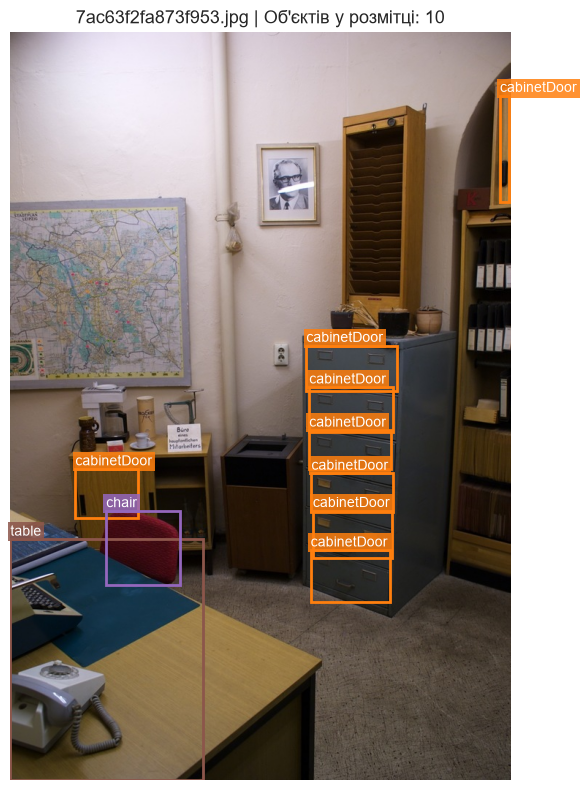

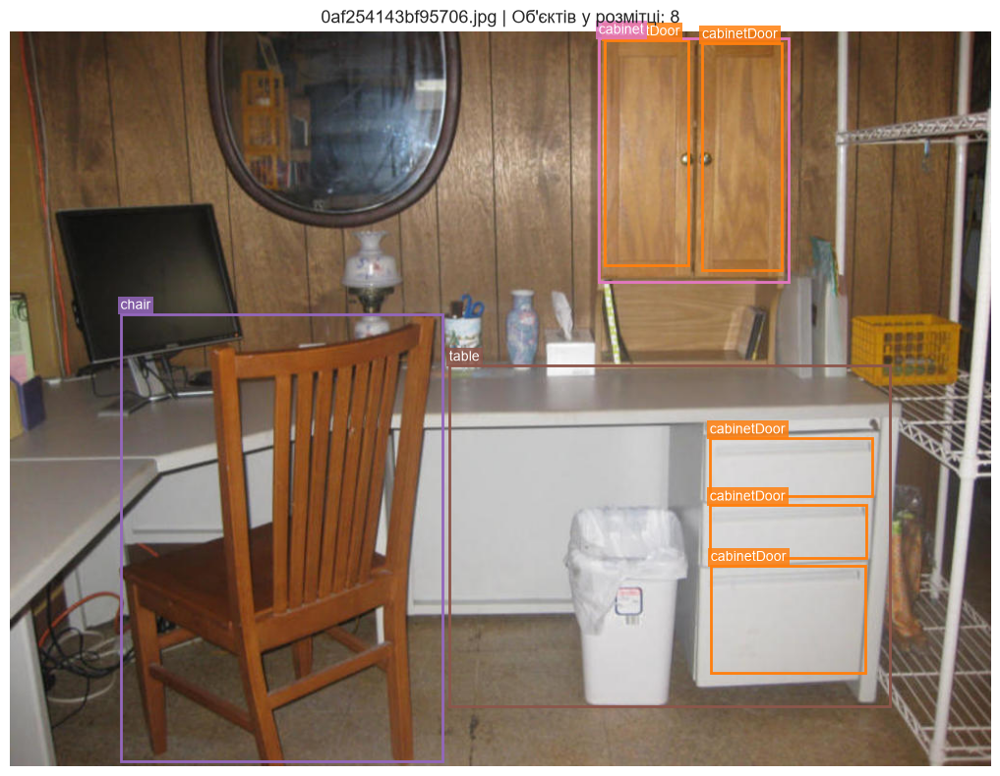

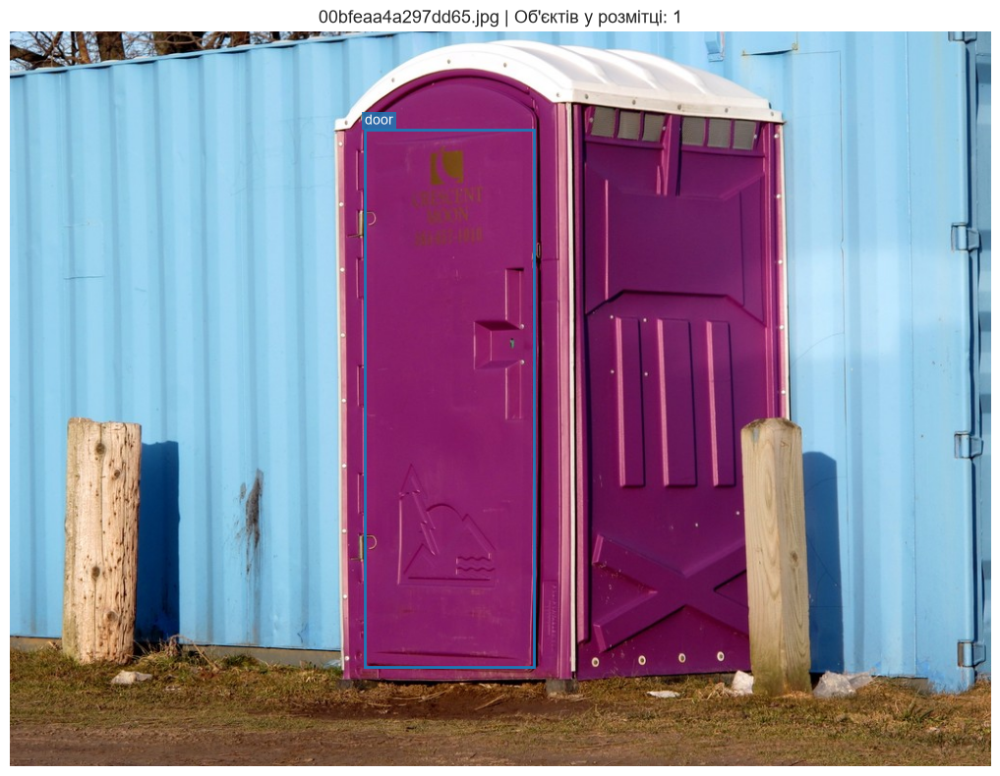

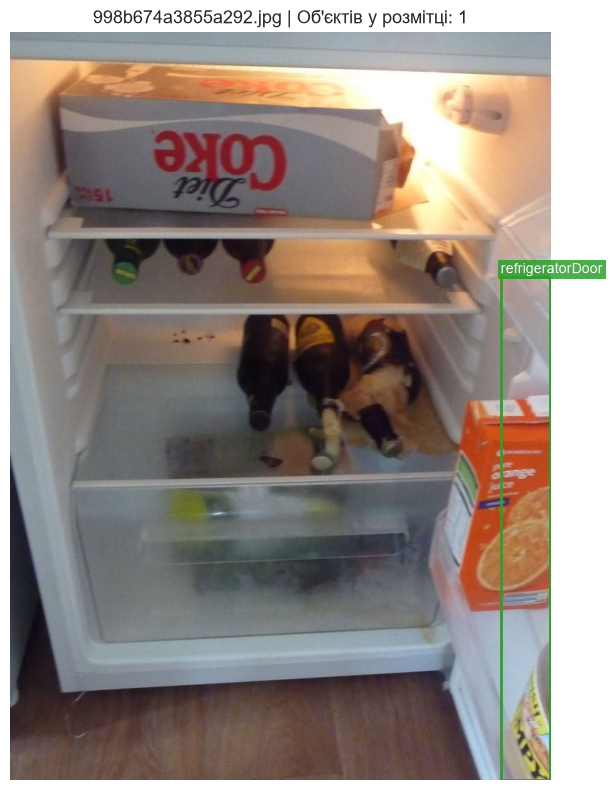

In [ ]:
# Візуалізація випадкових зображень із train-розділу

TRAIN_IMAGES_DIR = YOLO_DATA_DIR / "train" / "images"
TRAIN_LABELS_DIR = YOLO_DATA_DIR / "train" / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

train_images = sorted(
    image_path
    for image_path in TRAIN_IMAGES_DIR.iterdir()
    if image_path.suffix.lower() in image_extensions
)

random.seed(42)

sample_images = random.sample(train_images, k=min(4, len(train_images)))

for image_path in sample_images:
    label_path = TRAIN_LABELS_DIR / f"{image_path.stem}.txt"
    show_yolo_sample(image_path, label_path)


Клас: door (ID=0)


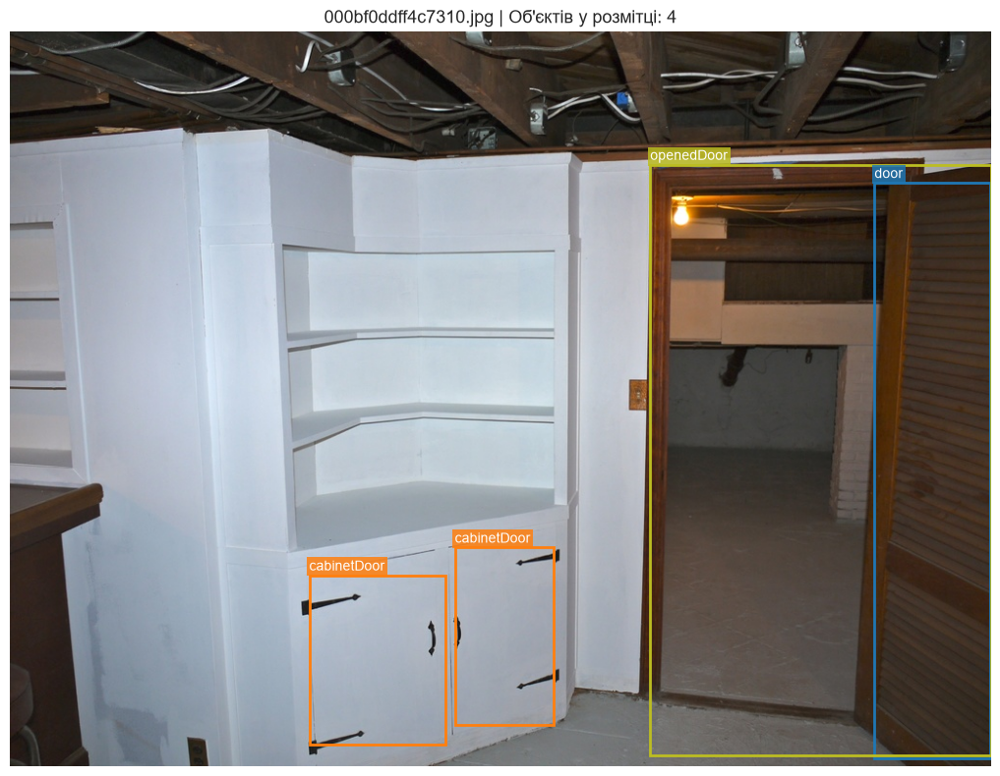

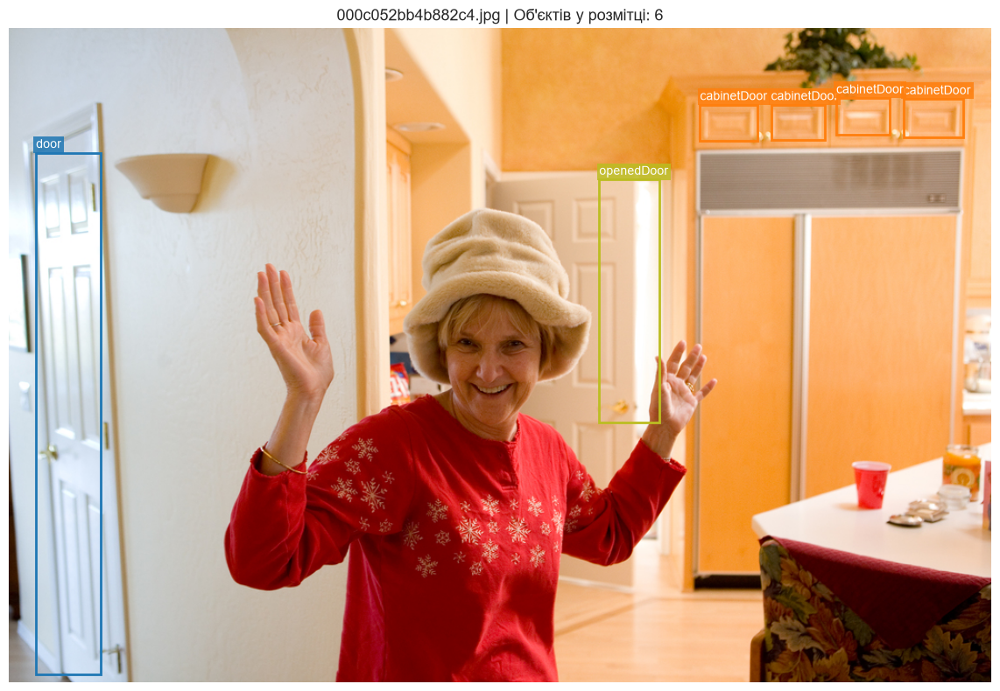


Клас: chair (ID=4)


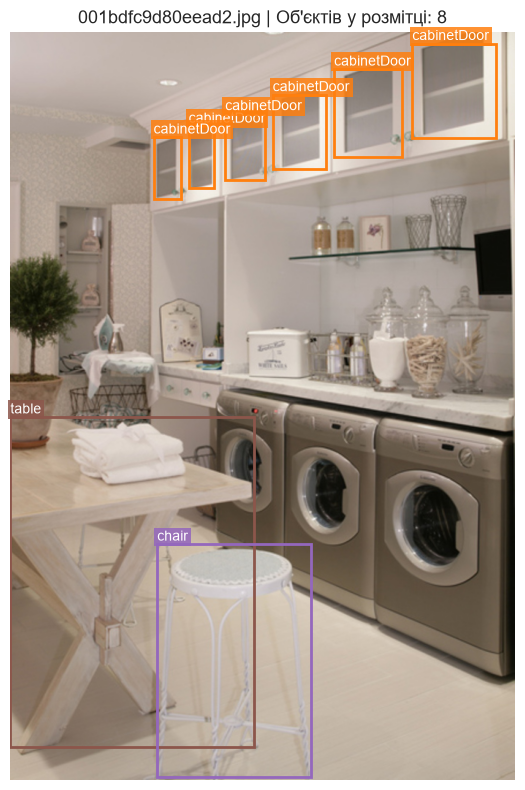

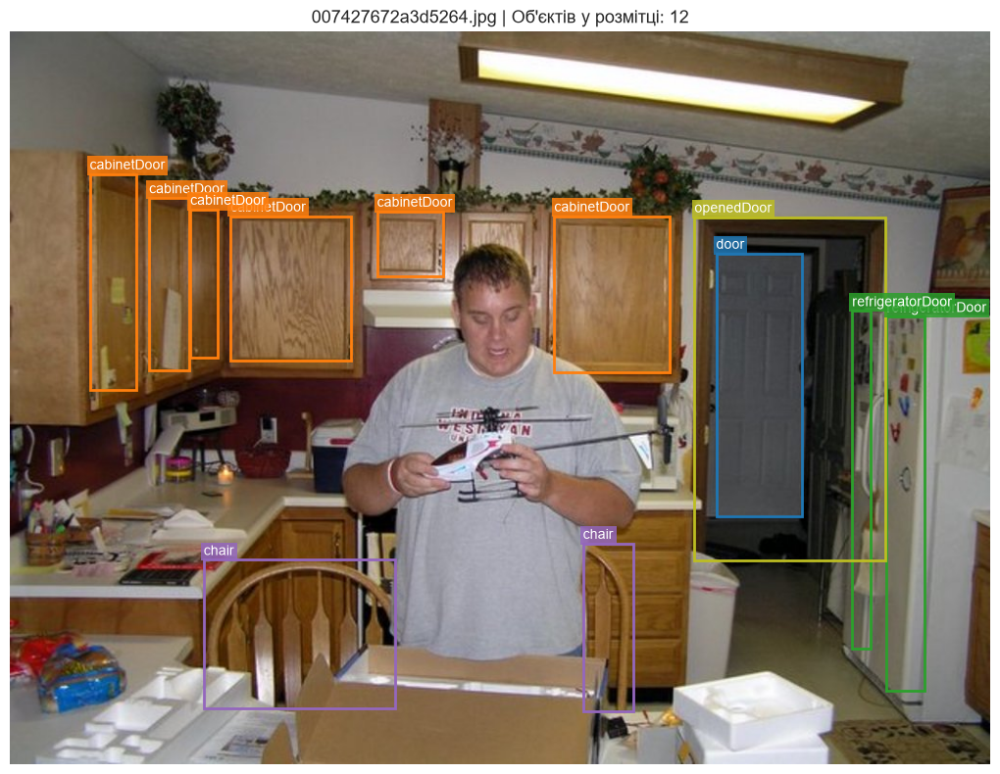


Клас: table (ID=5)


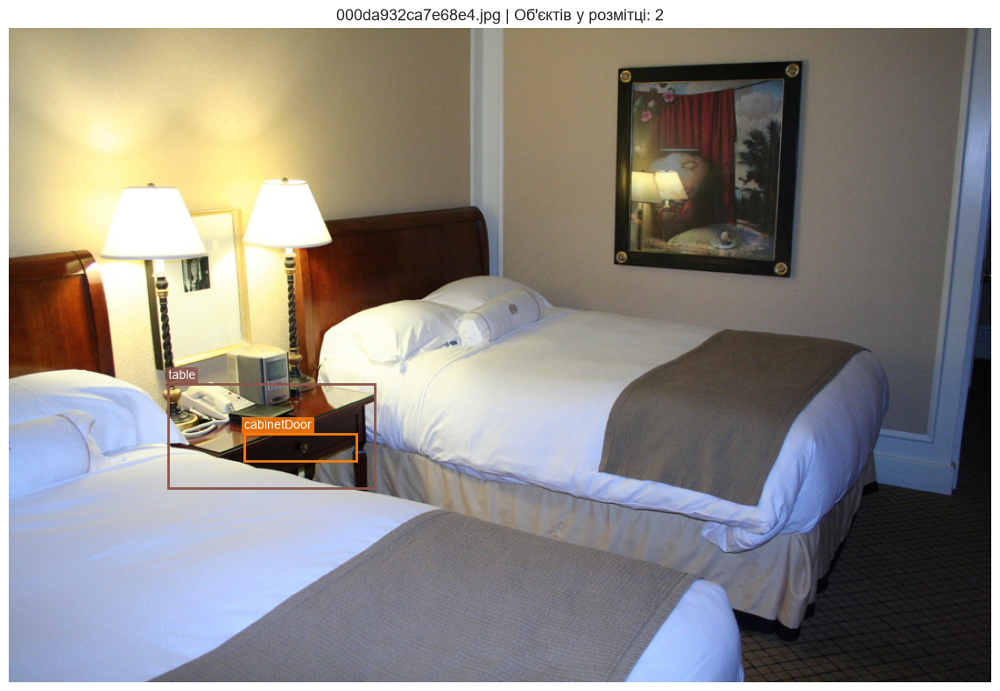

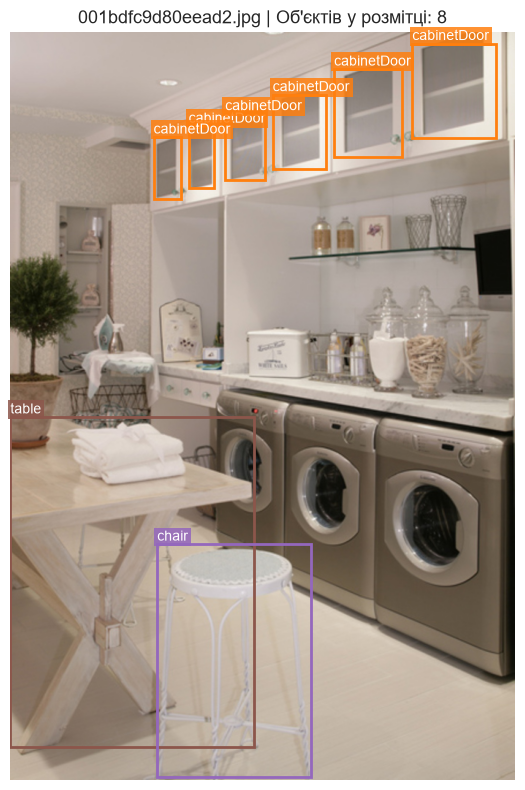

In [ ]:
# Цільова вибірка для door, chair, table

TARGET_CLASSES = {
    "door": 0,
    "chair": 4,
    "table": 5,
}

def find_images_with_class(
    images_dir: Path,
    labels_dir: Path,
    target_class_id: int,
    limit: int = 2,
):
    matches = []

    for image_path in sorted(images_dir.iterdir()):
        if image_path.suffix.lower() not in image_extensions:
            continue

        label_path = labels_dir / f"{image_path.stem}.txt"
        annotations = read_yolo_labels(label_path)

        if any(ann["class_id"] == target_class_id for ann in annotations):
            matches.append((image_path, label_path))

        if len(matches) >= limit:
            break

    return matches


for class_name, class_id in TARGET_CLASSES.items():
    print(f"\n{'=' * 70}")
    print(f"Клас: {class_name} (ID={class_id})")
    print("=" * 70)

    examples = find_images_with_class(
        TRAIN_IMAGES_DIR,
        TRAIN_LABELS_DIR,
        target_class_id=class_id,
        limit=2,
    )

    for image_path, label_path in examples:
        show_yolo_sample(image_path, label_path)

Зображення train без label-файлів: 4


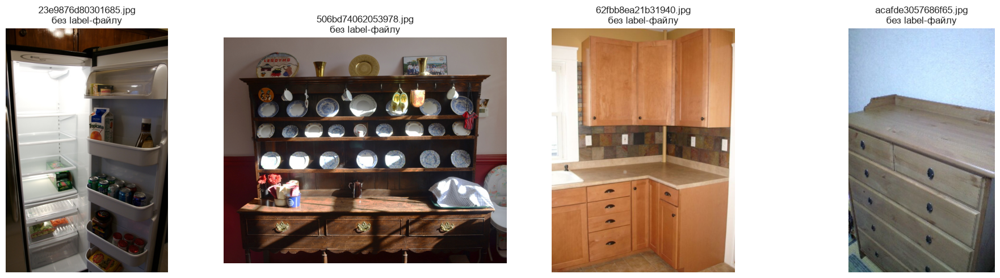

In [ ]:
# Перевірка наявності зображень без відповідних label-файлів у train-розділі

images_without_labels = [
    image_path
    for image_path in train_images
    if not (TRAIN_LABELS_DIR / f"{image_path.stem}.txt").exists()
]

print("Зображення train без label-файлів:", len(images_without_labels))

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(images_without_labels),
    figsize=(5 * max(1, len(images_without_labels)), 5),
)

if len(images_without_labels) == 1:
    axes = [axes]

for ax, image_path in zip(axes, images_without_labels):
    image_bgr = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    ax.imshow(image_rgb)
    ax.set_title(f"{image_path.name}\nбез label-файлу")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Виключення 4 неповністю розмічені train-зображення
from pathlib import Path

TRAIN_IMAGES_DIR = YOLO_DATA_DIR / "train" / "images"
TRAIN_LABELS_DIR = YOLO_DATA_DIR / "train" / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

all_train_images = sorted(
    image_path
    for image_path in TRAIN_IMAGES_DIR.iterdir()
    if image_path.is_file() and image_path.suffix.lower() in image_extensions
)

labeled_train_images = [
    image_path
    for image_path in all_train_images
    if (TRAIN_LABELS_DIR / f"{image_path.stem}.txt").exists()
]

unlabeled_train_images = [
    image_path
    for image_path in all_train_images
    if not (TRAIN_LABELS_DIR / f"{image_path.stem}.txt").exists()
]

train_list_path = YOLO_DATA_DIR / "train_labeled.txt"

with open(train_list_path, "w", encoding="utf-8") as file:
    for image_path in labeled_train_images:
        file.write(f"{image_path.resolve().as_posix()}\n")

print("Усього train-зображень:", len(all_train_images))
print("З коректними label-файлами:", len(labeled_train_images))
print("Виключено через пропущену розмітку:", len(unlabeled_train_images))

print("\nВиключені з навчання файли:")
for image_path in unlabeled_train_images:
    print("-", image_path.name)

print("\n✓ Створено файл списку train-зображень:")
print(train_list_path)

Усього train-зображень: 1012
З коректними label-файлами: 1008
Виключено через пропущену розмітку: 4

Виключені з навчання файли:
- 23e9876d80301685.jpg
- 506bd74062053978.jpg
- 62fbb8ea21b31940.jpg
- acafde3057686f65.jpg

✓ Створено файл списку train-зображень:
g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\train_labeled.txt


In [21]:
# Створення нового YAML-файлу для навчання з очищеними даними

CLEAN_YAML_PATH = YOLO_DATA_DIR / "data_train_clean.yaml"

clean_data_config = {
    "path": str(YOLO_DATA_DIR.resolve()).replace("\\", "/"),
    "train": "train_labeled.txt",
    "val": "valid/images",
    "test": "test/images",
    "nc": 10,
    "names": [
        "door",
        "cabinetDoor",
        "refrigeratorDoor",
        "window",
        "chair",
        "table",
        "cabinet",
        "couch",
        "openedDoor",
        "pole",
    ],
}

with open(CLEAN_YAML_PATH, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        clean_data_config,
        file,
        allow_unicode=True,
        sort_keys=False,
    )

print("✓ Створено:", CLEAN_YAML_PATH)
print()
print(CLEAN_YAML_PATH.read_text(encoding="utf-8"))

✓ Створено: g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\data_train_clean.yaml

path: G:/GOIT/GitHub/Feliz-ua-goit-dlcv-hw08/data/indoor_objects_yolo
train: train_labeled.txt
val: valid/images
test: test/images
nc: 10
names:
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole



In [22]:
# Перевірка нового YAML-файлу за допомогою Ultralytics
from ultralytics.data.utils import check_det_dataset

clean_dataset_info = check_det_dataset(str(CLEAN_YAML_PATH))

print("✓ Очищену конфігурацію успішно прочитано.")
print("train:", clean_dataset_info["train"])
print("val:", clean_dataset_info["val"])
print("test:", clean_dataset_info["test"])
print("names:", clean_dataset_info["names"])

✓ Очищену конфігурацію успішно прочитано.
train: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\train_labeled.txt
val: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\valid\images
test: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images
names: {0: 'door', 1: 'cabinetDoor', 2: 'refrigeratorDoor', 3: 'window', 4: 'chair', 5: 'table', 6: 'cabinet', 7: 'couch', 8: 'openedDoor', 9: 'pole'}


## Параметри першого запуску

| Параметр   | Значення            | Причина                                                                  |
| ---------- | ------------------- | ------------------------------------------------------------------------ |
| model      | yolov8s.pt          | Переднавчена компактна модель                                            |
| imgsz      | 640                 | Стандартний розмір для детекції; достатній для дверей, стільців і столів |
| epochs     | 50                  | Достатньо для першої оцінки без надмірних витрат часу                    |
| batch      | 8                   | Безпечний старт для GTX 1070 Ti, 8 ГБ VRAM                               |
| device     | 0                   | Явно використовує перший GPU                                             |
| patience   | 20                  | Раннє зупинення, якщо валідаційна якість перестане поліпшуватись         |
| optimizer  | auto                | Ultralytics вибере оптимізатор і базові параметри                        |
| pretrained | True                | Використання COCO-переднавчених ваг                                      |
| cache      | False               | Не завантажує весь датасет у RAM; стабільніше для локальної машини       |
| workers    | 4                   | Помірна кількість процесів для Windows                                   |
| seed       | 42                  | Відтворюваність експерименту                                             |
| project    | runs/indoor_objects | Зрозуміла структура результатів                                          |
| name       | yolov8s_baseline    | Назва конкретного запуску                                                |

In [ ]:
# Перевірка доступності GPU та VRAM

import torch

assert torch.cuda.is_available(), "CUDA не знайдено — перевір PyTorch і драйвер NVIDIA."

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)
print(
    "Доступно VRAM:",
    f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
)

torch.cuda.empty_cache()
print("✓ GPU готовий до навчання.")

GPU: NVIDIA GeForce GTX 1070 Ti
CUDA: 12.6
Доступно VRAM: 8.00 GB
✓ GPU готовий до навчання.


In [ ]:
# Завантаження моделі YOLOv8s

from ultralytics import YOLO

MODEL_NAME = "yolov8s.pt"

model = YOLO(MODEL_NAME)

print("✓ Модель завантажено:", MODEL_NAME)
model.info()

✓ Модель завантажено: yolov8s.pt
YOLOv8s summary: 129 layers, 11,166,560 parameters, 0 gradients, 28.8 GFLOPs


(129, 11166560, 0, 28.8119296)

In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
CLEAN_YAML_PATH = (
    PROJECT_DIR
    / "data"
    / "indoor_objects_yolo"
    / "data_train_clean.yaml"
)

RUNS_DIR = PROJECT_DIR / "runs"

results = model.train(
    data=str(CLEAN_YAML_PATH),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    optimizer="auto",
    pretrained=True,
    patience=20,
    cache=False,
    seed=42,
    project=str(RUNS_DIR / "indoor_objects"),
    name="yolov8s_baseline",
    exist_ok=True,
    plots=True,
    verbose=True,
)Validating G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\runs\indoor_objects\yolov8s_baseline\weights\best.pt...
Ultralytics 8.4.168  Python-3.14.7 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1070 Ti, 8192MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.8it/s 3.1s0.2s
                   all        230       1289      0.501      0.531      0.487      0.289
                  door         63         97      0.482      0.629       0.55      0.327
           cabinetDoor         99        765      0.737      0.797      0.808      0.461
      refrigeratorDoor         85        192      0.727      0.797      0.804      0.519
                window         39         91      0.396      0.318      0.309      0.169
                 chair         24         49      0.726      0.633      0.672      0.337
                 table         30         40      0.219      0.175      0.166     0.0778
               cabinet         28         32      0.268      0.438      0.394      0.305
                 couch          1          1      0.403      0.806      0.497      0.398
            openedDoor         13         13      0.196      0.385      0.205      0.107
                  pole          4          9      0.852      0.333      0.462      0.187
Speed: 0.2ms preprocess, 6.1ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\runs\indoor_objects\yolov8s_baseline

Ultralytics 8.4.168  Python-3.14.7 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1070 Ti, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\data_train_clean.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=

### Підсумки навчання:

На валідаційному наборі модель досягла mAP@50 = 0.487 та mAP@50–95 = 0.289. Це хороший базовий результат для відносно малого й незбалансованого датасету: модель уже впевнено виявляє двері та стільці, але клас table поки що слабкий.

| Параметр              | Значення                                              |
| --------------------- | ----------------------------------------------------- |
| Архітектура           | YOLOv8s                                               |
| Переднавчені ваги     | yolov8s.pt                                            |
| Кількість класів      | 10                                                    |
| Train-зображення      | 1008                                                  |
| Validation-зображення | 230                                                   |
| Епохи                 | 50                                                    |
| Розмір зображення     | 640 × 640                                             |
| Batch size            | 8                                                     |
| GPU                   | NVIDIA GeForce GTX 1070 Ti, 8 ГБ                      |
| Час навчання          | 0.478 год, приблизно 28.7 хв                          |
| Використана VRAM      | приблизно 2.69 ГБ                                     |
| best.pt               | 22.5 МБ                                               |
| Швидкість inference   | 6.1 мс на зображення без preprocessing/postprocessing |

Модель використала лише приблизно 2.7 ГБ із 8 ГБ VRAM, тому надалі можна буде експериментувати з batch=16 або з вищою роздільною здатністю, якщо це стане потрібним для столів, малих об’єктів чи далеких деталей.

### Метрики валідації
Фінальна перевірка виконувалась на найкращих вагах best.pt, а не на last.pt.

| Клас             | Зображень | Об’єктів | Precision | Recall | mAP@50 | mAP@50–95 |
| ---------------- | --------- | -------- | --------- | ------ | ------ | --------- |
| Усі класи        | 230       | 1289     | 0.501     | 0.531  | 0.487  | 0.289     |
| door             | 63        | 97       | 0.482     | 0.629  | 0.550  | 0.327     |
| cabinetDoor      | 99        | 765      | 0.737     | 0.797  | 0.808  | 0.461     |
| refrigeratorDoor | 85        | 192      | 0.727     | 0.797  | 0.804  | 0.519     |
| window           | 39        | 91       | 0.396     | 0.318  | 0.309  | 0.169     |
| chair            | 24        | 49       | 0.726     | 0.633  | 0.672  | 0.337     |
| table            | 30        | 40       | 0.219     | 0.175  | 0.166  | 0.078     |
| cabinet          | 28        | 32       | 0.268     | 0.438  | 0.394  | 0.305     |
| couch            | 1         | 1        | 0.403     | 0.806  | 0.497  | 0.398     |
| openedDoor       | 13        | 13       | 0.196     | 0.385  | 0.205  | 0.107     |
| pole             | 4         | 9        | 0.852     | 0.333  | 0.462  | 0.187     |

### Досягнення цілей
Цілі досягнуто частково й переконливо для мінімальної базової функціональності.
Початкова вимога — надійно визначати хоча б третину класів, особливо поширені предмети: двері, стільці та столи.

door: mAP@50 = 0.550, recall = 0.629 — клас детектується на прийнятному рівні.

chair: mAP@50 = 0.672, precision = 0.726, recall = 0.633 — сильний результат.

table: mAP@50 = 0.166, recall = 0.175 — вимогу надійного розпізнавання столів поки що не виконано.

Додатково сильні класи: cabinetDoor (0.808) та refrigeratorDoor (0.804).

Отже, модель уже добре працює щонайменше з чотирма класами: door, chair, cabinetDoor, refrigeratorDoor. Це 4 з 10 класів, тобто більше ніж одна третина. Проте формулювання про ключові класи варто подати чесно: двері й стільці розпізнаються прийнятно, а столи потребують покращення.

Первинний аналіз кривих
Навчальні втрати протягом 50 епох монотонно знижувались:
box_loss: приблизно з 1.63 до 0.89;
cls_loss: приблизно з 2.70 до 0.54;
dfl_loss: приблизно з 1.47 до 1.02.
Водночас валідаційний mAP@50 зростав нерівномірно, але загальний прогрес є:
епоха 1: mAP@50 = 0.254;
епоха 10: mAP@50 = 0.405;
епоха 22: mAP@50 = 0.472;
найкраща модель: mAP@50 = 0.487;
наприкінці 50-ї епохи: mAP@50 = 0.459.

Це не виглядає як різке критичне перенавчання: training loss знижується, а валідаційні метрики коливаються через малий розмір набору, нерівний розподіл класів і агресивні аугментації. best.pt було збережено на кращій епосі з mAP@50 близько 0.487, а не на фінальній 50-й епосі.


In [26]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

RUN_DIR = (
    PROJECT_DIR
    / "runs"
    / "indoor_objects"
    / "yolov8s_baseline"
)

print("Каталог результатів:")
print(RUN_DIR)
print("\nНаявні файли:")

for file_path in sorted(RUN_DIR.iterdir()):
    if file_path.is_file():
        print("📄", file_path.name)
    else:
        print("📁", file_path.name)

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

print("\nПеревірка ваг:")
print(f"best.pt існує: {BEST_WEIGHTS.exists()}")
print(f"last.pt існує: {LAST_WEIGHTS.exists()}")

Каталог результатів:
g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\runs\indoor_objects\yolov8s_baseline

Наявні файли:
📄 args.yaml
📄 BoxF1_curve.png
📄 BoxP_curve.png
📄 BoxPR_curve.png
📄 BoxR_curve.png
📄 confusion_matrix.png
📄 confusion_matrix_normalized.png
📄 labels.jpg
📄 results.csv
📄 results.png
📄 train_batch0.jpg
📄 train_batch1.jpg
📄 train_batch2.jpg
📄 train_batch5040.jpg
📄 train_batch5041.jpg
📄 train_batch5042.jpg
📄 val_batch0_labels.jpg
📄 val_batch0_pred.jpg
📄 val_batch1_labels.jpg
📄 val_batch1_pred.jpg
📄 val_batch2_labels.jpg
📄 val_batch2_pred.jpg
📁 weights

Перевірка ваг:
best.pt існує: True
last.pt існує: True


In [ ]:
# Окрема оцінка best.pt на test

from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path.cwd()

RUN_DIR = (
    PROJECT_DIR
    / "runs"
    / "indoor_objects"
    / "yolov8s_baseline"
)

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"

CLEAN_YAML_PATH = (
    PROJECT_DIR
    / "data"
    / "indoor_objects_yolo"
    / "data_train_clean.yaml"
)

TEST_PROJECT_DIR = PROJECT_DIR / "runs" / "indoor_objects_test"

assert BEST_WEIGHTS.exists(), f"Не знайдено ваги: {BEST_WEIGHTS}"
assert CLEAN_YAML_PATH.exists(), f"Не знайдено YAML: {CLEAN_YAML_PATH}"
assert torch.cuda.is_available(), "CUDA недоступна"

best_model = YOLO(str(BEST_WEIGHTS))

test_metrics = best_model.val(
    data=str(CLEAN_YAML_PATH),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    conf=0.001,
    iou=0.7,
    plots=True,
    save_json=False,
    project=str(TEST_PROJECT_DIR),
    name="yolov8s_baseline_test",
    exist_ok=True,
    verbose=True,
)

print("\n===== Загальні test-метрики =====")
print(f"Precision:  {test_metrics.box.mp:.4f}")
print(f"Recall:     {test_metrics.box.mr:.4f}")
print(f"mAP@50:     {test_metrics.box.map50:.4f}")
print(f"mAP@50-95:  {test_metrics.box.map:.4f}")

print("\n===== Метрики за класами =====")
class_names = test_metrics.names

for class_id, class_name in class_names.items():
    print(
        f"{class_id:>2} | {class_name:<18} | "
        f"P={test_metrics.box.p[class_id]:.4f} | "
        f"R={test_metrics.box.r[class_id]:.4f} | "
        f"AP50={test_metrics.box.ap50[class_id]:.4f} | "
        f"AP50-95={test_metrics.box.ap[class_id].mean():.4f}"
    )
    

Ultralytics 8.4.168  Python-3.14.7 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1070 Ti, 8192MiB)
Model summary (fused): 72 layers, 11,129,454 parameters, 0 gradients, 28.5 GFLOPs
WARNING val: Slow image access detected (ping: 9.98.9 ms, read: 24.78.4 MB/s, size: 335.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\labels... 104 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 107/107 389.3it/s 0.3s1s
val: New cache created: G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.5it/s 4.0s0.2s
                   all        107        550      0.486      0.386      0.382      0.224
                  door         25         34      0.441      0.441      0.331      0.169

In [28]:
# Збереження test-метрик у CSV-файл

test_rows = []

for class_id, class_name in test_metrics.names.items():
    test_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "precision": float(test_metrics.box.p[class_id]),
        "recall": float(test_metrics.box.r[class_id]),
        "f1_score": float(test_metrics.box.f1[class_id]),
        "mAP50": float(test_metrics.box.ap50[class_id]),
        "mAP50_95": float(test_metrics.box.ap[class_id].mean()),
    })

test_metrics_df = pd.DataFrame(test_rows)

display(
    test_metrics_df.style.format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50_95": "{:.3f}",
    })
)

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

test_metrics_csv = REPORTS_DIR / "yolov8s_baseline_test_metrics.csv"
test_metrics_df.to_csv(test_metrics_csv, index=False, encoding="utf-8-sig")

print(f"✓ Таблицю test-метрик збережено: {test_metrics_csv}")

,class_id,class_name,precision,recall,f1_score,mAP50,mAP50_95
0,0,door,0.441,0.441,0.441,0.331,0.169
1,1,cabinetDoor,0.577,0.510,0.542,0.492,0.192
2,2,refrigeratorDoor,0.217,1.000,0.357,0.995,0.846
3,3,window,0.690,0.460,0.552,0.489,0.272
4,4,chair,0.611,0.402,0.485,0.368,0.198
5,5,table,0.282,0.234,0.256,0.151,0.066
6,6,cabinet,0.482,0.269,0.346,0.276,0.179
7,7,couch,0.448,0.224,0.299,0.221,0.096
8,8,openedDoor,0.797,0.197,0.316,0.271,0.102
9,9,pole,0.317,0.125,0.179,0.223,0.122


✓ Таблицю test-метрик збережено: g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\reports\yolov8s_baseline_test_metrics.csv


### Висновок для тестової вибірки:

- Найкраща стабільна практична поведінка серед класів із неаномальними показниками: cabinetDoor, window, chair.
- door детектується, але з обмеженою якістю: mAP@50 = 0.331, F1 = 0.441.
- chair має прийнятну precision (0.611), але recall = 0.402: модель пропускає приблизно значну частину стільців.
- table залишається найслабшим із ключових класів: mAP@50 = 0.151, recall = 0.234.
- openedDoor має високу precision (0.797), але низький recall (0.197): коли модель прогнозує цей клас, прогноз часто правильний, але вона рідко його знаходить.
- pole і couch поки не можна вважати надійними через низьку кількість розмічених прикладів у всьому датасеті.

In [29]:


TEST_IMAGES_DIR = YOLO_DATA_DIR / "test" / "images"
TEST_LABELS_DIR = YOLO_DATA_DIR / "test" / "labels"

test_class_counter = Counter()
test_image_counter = Counter()
test_images_with_objects = 0
test_images_without_labels = []

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_images = sorted(
    image_path
    for image_path in TEST_IMAGES_DIR.iterdir()
    if image_path.is_file() and image_path.suffix.lower() in image_extensions
)

for image_path in test_images:
    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"

    if not label_path.exists():
        test_images_without_labels.append(image_path.name)
        continue

    lines = [
        line.strip()
        for line in label_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

    if lines:
        test_images_with_objects += 1

    present_classes = set()

    for line in lines:
        class_id = int(line.split()[0])
        test_class_counter[class_id] += 1
        present_classes.add(class_id)

    for class_id in present_classes:
        test_image_counter[class_id] += 1

test_distribution_df = pd.DataFrame([
    {
        "class_id": class_id,
        "class_name": CLASS_NAMES[class_id],
        "test_images": test_image_counter[class_id],
        "test_instances": test_class_counter[class_id],
    }
    for class_id in range(len(CLASS_NAMES))
])

print(f"Усього test-зображень: {len(test_images)}")
print(f"Test-зображень з хоча б одним об'єктом: {test_images_with_objects}")
print(f"Зображень без label-файлу: {len(test_images_without_labels)}")
print("Файли без label-файлу:", test_images_without_labels)

display(test_distribution_df)

Усього test-зображень: 107
Test-зображень з хоча б одним об'єктом: 104
Зображень без label-файлу: 3
Файли без label-файлу: ['1139.png', '1167.png', '831.png']


,class_id,class_name,test_images,test_instances
0,0,door,25,34
1,1,cabinetDoor,42,179
2,2,refrigeratorDoor,1,2
3,3,window,49,63
4,4,chair,38,87
5,5,table,41,47
6,6,cabinet,44,52
7,7,couch,31,58
8,8,openedDoor,18,20
9,9,pole,3,8


In [30]:
print("===== Загальні test-метрики =====")
print(f"Precision:  {test_metrics.box.mp:.4f}")
print(f"Recall:     {test_metrics.box.mr:.4f}")
print(f"F1-score:   {test_metrics.box.f1.mean():.4f}")
print(f"mAP@50:     {test_metrics.box.map50:.4f}")
print(f"mAP@50-95:  {test_metrics.box.map:.4f}")

===== Загальні test-метрики =====
Precision:  0.4864
Recall:     0.3864
F1-score:   0.3773
mAP@50:     0.3816
mAP@50-95:  0.2242


Test-оцінку завершено: baseline YOLOv8s має mAP@50 = 0.3816, mAP@50–95 = 0.2242, precision = 0.4864 і recall = 0.3864. Це підтверджує базову здатність моделі знаходити частину indoor-об’єктів, але загальна якість ще помірна й потребує вдосконалення.


Матриця кількостей:


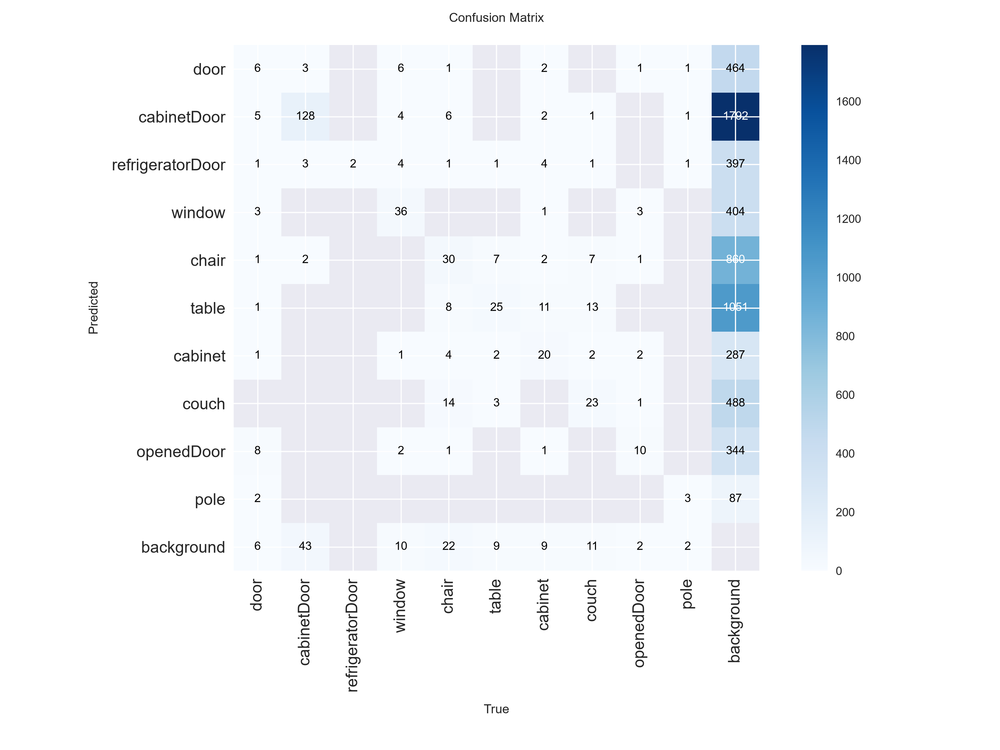


Нормалізована матриця:


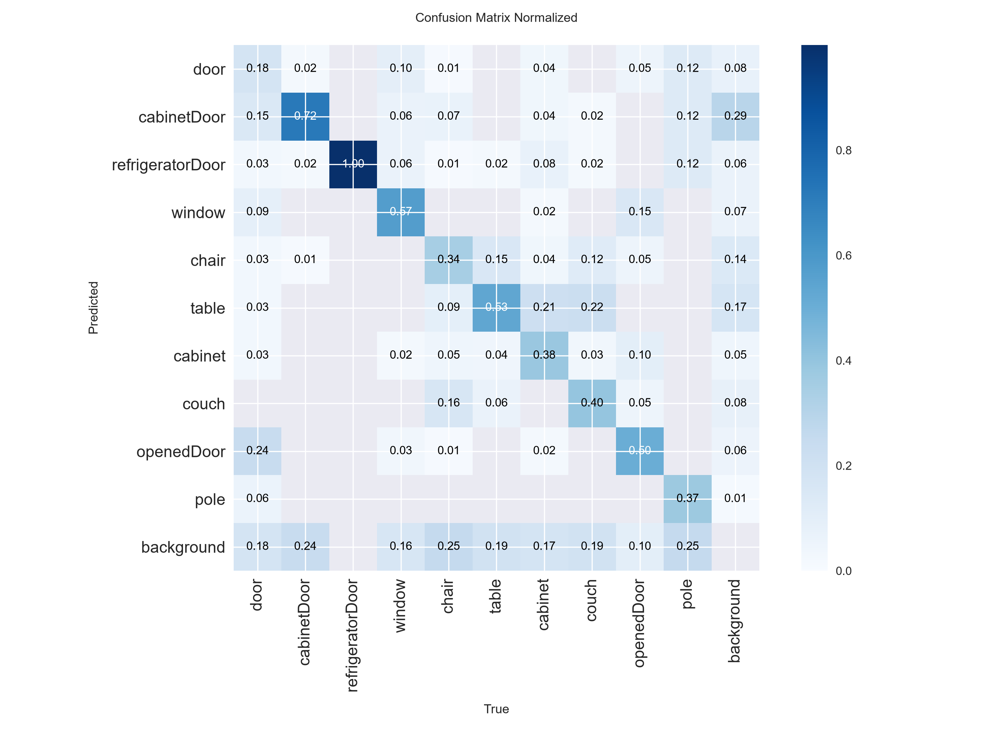

In [36]:
from IPython.display import Image, display

DISPLAY_WIDTH = 1000  

print("\nМатриця кількостей:")
display(
    Image(
        filename=str(confusion_matrix_path),
        width=DISPLAY_WIDTH
    )
)

print("\nНормалізована матриця:")
display(
    Image(
        filename=str(confusion_matrix_normalized_path),
        width=DISPLAY_WIDTH
    )
)

Матриця показує, що модель уже розрізняє частину класів, але має багато пропусків через background і плутає візуально схожі об’єкти. Найбільша проблема — класи table, chair, door та openedDoor.

Висновок за матрицею
Baseline YOLOv8s:
- добре навчився на масовому класі cabinetDoor;
- прийнятно розрізняє window і chair;
- частково працює з door;
- часто плутає door та openedDoor;
- слабко розпізнає table;
- часто пропускає об’єкти через малу кількість прикладів, дисбаланс і складні перекриття;

In [37]:
# Прогнозування на тестових зображеннях за допомогою best.pt


PROJECT_DIR = Path.cwd()

YOLO_DATA_DIR = PROJECT_DIR / "data" / "indoor_objects_yolo"
TEST_IMAGES_DIR = YOLO_DATA_DIR / "test" / "images"

RUN_DIR = (
    PROJECT_DIR
    / "runs"
    / "indoor_objects"
    / "yolov8s_baseline"
)

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"

PREDICT_PROJECT_DIR = PROJECT_DIR / "runs" / "indoor_objects_predictions"

assert TEST_IMAGES_DIR.exists(), f"Не знайдено test images: {TEST_IMAGES_DIR}"
assert BEST_WEIGHTS.exists(), f"Не знайдено best.pt: {BEST_WEIGHTS}"

best_model = YOLO(str(BEST_WEIGHTS))

prediction_results = best_model.predict(
    source=str(TEST_IMAGES_DIR),
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(PREDICT_PROJECT_DIR),
    name="test_predictions_conf025",
    exist_ok=True,
    verbose=True,
)

PREDICTIONS_DIR = (
    PREDICT_PROJECT_DIR
    / "test_predictions_conf025"
)

print("\n✓ Прогнози збережено у:")
print(PREDICTIONS_DIR)


image 1/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1003.png: 480x640 2 doors, 1 openedDoor, 15.9ms
image 2/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1014.png: 480x640 (no detections), 16.6ms
image 3/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1015.png: 480x640 (no detections), 18.7ms
image 4/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1020.png: 480x640 1 openedDoor, 14.9ms
image 5/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1021.png: 480x640 1 table, 18.3ms
image 6/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1023.png: 480x640 1 window, 1 chair, 16.7ms
image 7/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\images\1026.png: 480x640 2 doors, 1 window, 1 table, 3 couchs, 16.2ms
image 8/107 g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_

Кількість збережених прогнозів: 107
1310.jpg


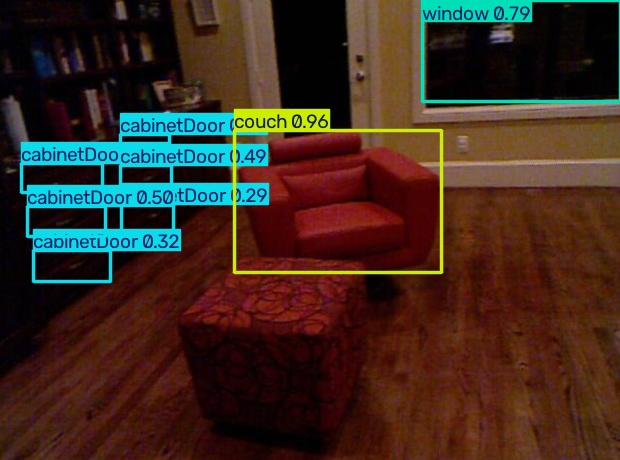

1045.jpg


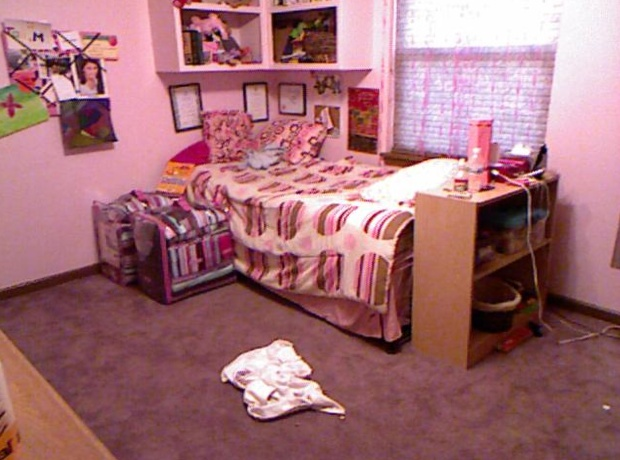

1020.jpg


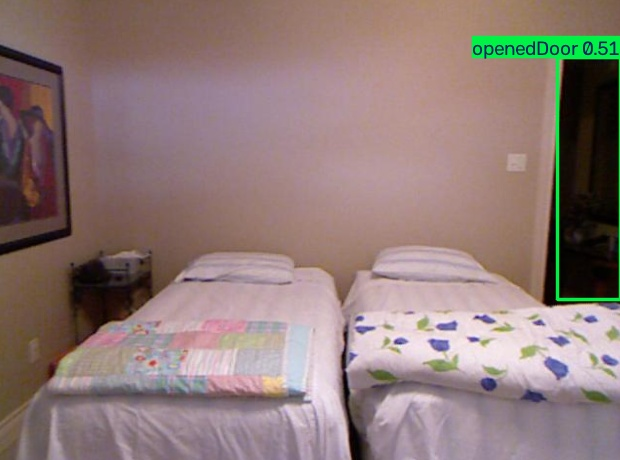

1345.jpg


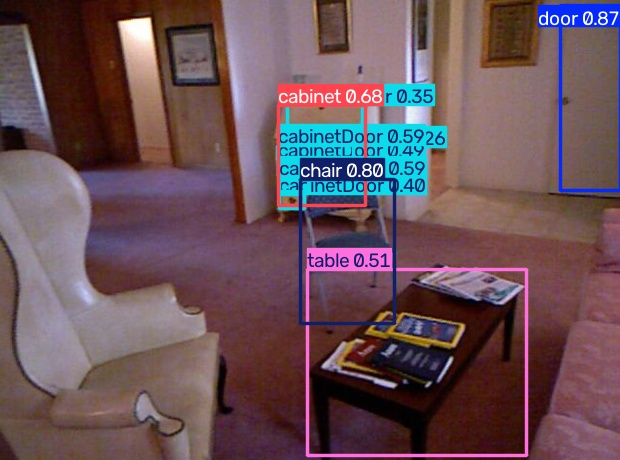

1113.jpg


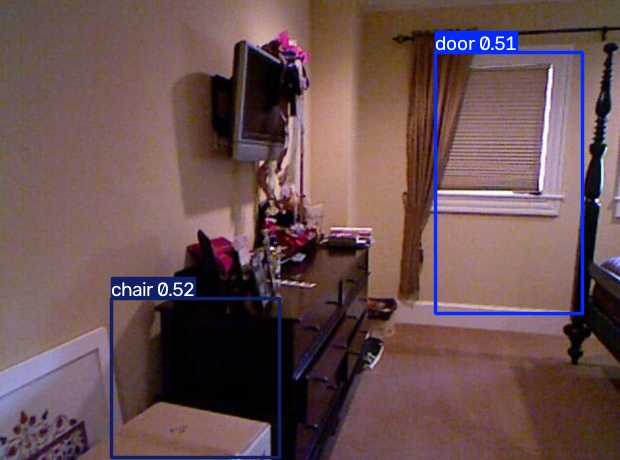

1101.jpg


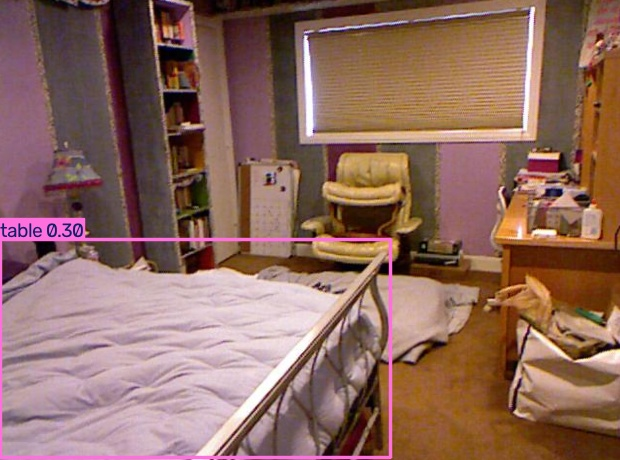

1093.jpg


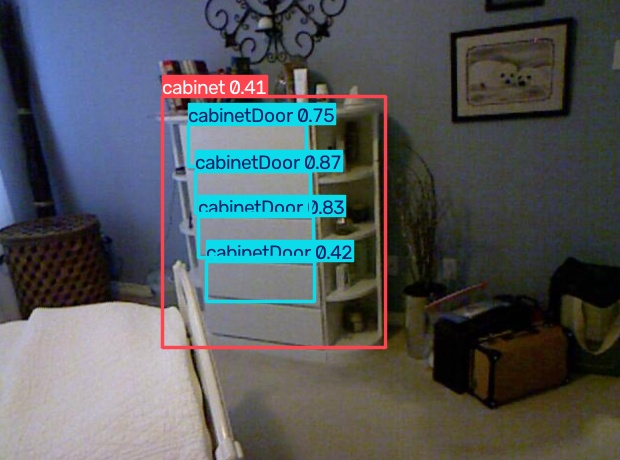

1052.jpg


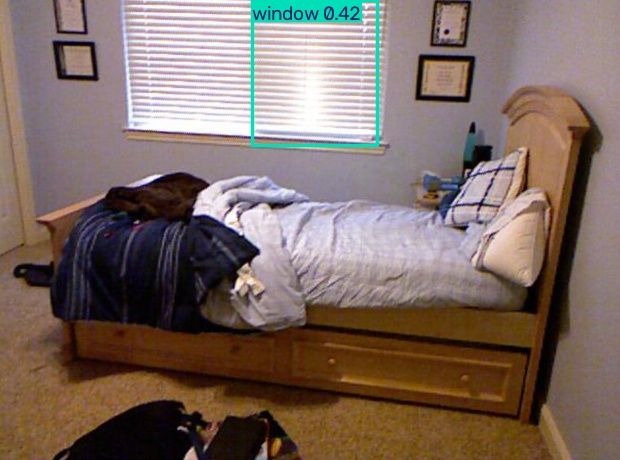

In [38]:
# Виведення випадкових прогнозів із тестових зображень

import random


image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

predicted_images = sorted(
    image_path
    for image_path in PREDICTIONS_DIR.iterdir()
    if image_path.is_file() and image_path.suffix.lower() in image_extensions
)

print("Кількість збережених прогнозів:", len(predicted_images))

random.seed(42)

sample_size = min(8, len(predicted_images))
sample_predictions = random.sample(predicted_images, k=sample_size)

for image_path in sample_predictions:
    print(image_path.name)
    display(Image(filename=str(image_path), width=700))

За рандомними прикладами видно, що модель уже знаходить частину об’єктів, але також має і проблеми: надлишкові детекції cabinetDoor, плутанину між дверима та вікнами, а також слабке розпізнавання столів і частково прихованих об’єктів. Також у деяких кадрів немає прогнозів навіть для видимих цільових об’єктів.

===== Найкраща епоха за mAP@50-95 =====
Epoch: 46
mAP@50: 0.4863
mAP@50-95: 0.2888
Precision: 0.5003
Recall: 0.5311

===== Втрати на найкращій епосі =====
Train box loss: 0.9498
Train cls loss: 0.5924
Train dfl loss: 1.0469
Val box loss: 1.4139
Val cls loss: 1.2649
Val dfl loss: 1.3626


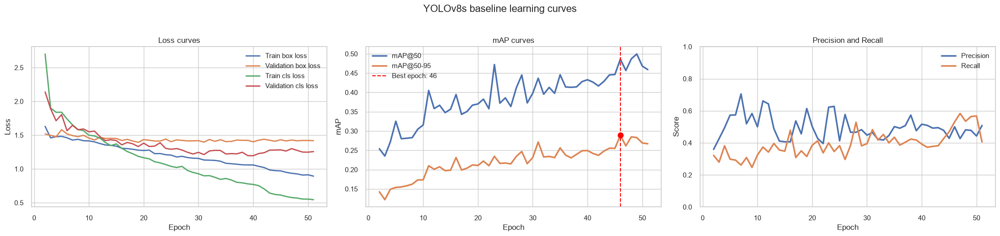

In [41]:
# Перегляд результатів навчання та оцінки у CSV-файлі

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd()

RUN_DIR = (
    PROJECT_DIR
    / "runs"
    / "indoor_objects"
    / "yolov8s_baseline"
)

RESULTS_CSV_PATH = RUN_DIR / "results.csv"

assert RESULTS_CSV_PATH.exists(), f"Файл не знайдено: {RESULTS_CSV_PATH}"

# Завантаження метрик за всі епохи
results_df = pd.read_csv(RESULTS_CSV_PATH)
results_df.columns = results_df.columns.str.strip()

# Знаходимо epoch з найбільшим mAP@50-95
metric_column = "metrics/mAP50-95(B)"
best_epoch_row = results_df.loc[results_df[metric_column].idxmax()]
best_epoch = int(best_epoch_row["epoch"]) + 1

print("===== Найкраща епоха за mAP@50-95 =====")
print(f"Epoch: {best_epoch}")
print(f"mAP@50: {best_epoch_row['metrics/mAP50(B)']:.4f}")
print(f"mAP@50-95: {best_epoch_row['metrics/mAP50-95(B)']:.4f}")
print(f"Precision: {best_epoch_row['metrics/precision(B)']:.4f}")
print(f"Recall: {best_epoch_row['metrics/recall(B)']:.4f}")

print("\n===== Втрати на найкращій епосі =====")
print(f"Train box loss: {best_epoch_row['train/box_loss']:.4f}")
print(f"Train cls loss: {best_epoch_row['train/cls_loss']:.4f}")
print(f"Train dfl loss: {best_epoch_row['train/dfl_loss']:.4f}")
print(f"Val box loss: {best_epoch_row['val/box_loss']:.4f}")
print(f"Val cls loss: {best_epoch_row['val/cls_loss']:.4f}")
print(f"Val dfl loss: {best_epoch_row['val/dfl_loss']:.4f}")

# Вісь X: 1..50, а не 0..49
epochs = results_df["epoch"] + 1

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 3, figsize=(22, 5))

# 1. Loss curves
axes[0].plot(
    epochs, results_df["train/box_loss"],
    label="Train box loss", linewidth=2
)
axes[0].plot(
    epochs, results_df["val/box_loss"],
    label="Validation box loss", linewidth=2
)
axes[0].plot(
    epochs, results_df["train/cls_loss"],
    label="Train cls loss", linewidth=2
)
axes[0].plot(
    epochs, results_df["val/cls_loss"],
    label="Validation cls loss", linewidth=2
)

axes[0].set_title("Loss curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2. mAP curves
axes[1].plot(
    epochs,
    results_df["metrics/mAP50(B)"],
    label="mAP@50",
    linewidth=2.5,
)
axes[1].plot(
    epochs,
    results_df["metrics/mAP50-95(B)"],
    label="mAP@50-95",
    linewidth=2.5,
)

axes[1].axvline(
    best_epoch,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Best epoch: {best_epoch}",
)
axes[1].scatter(
    best_epoch,
    best_epoch_row["metrics/mAP50-95(B)"],
    color="red",
    s=70,
    zorder=3,
)

axes[1].set_title("mAP curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mAP")
axes[1].legend()

# 3. Precision / Recall
axes[2].plot(
    epochs,
    results_df["metrics/precision(B)"],
    label="Precision",
    linewidth=2.5,
)
axes[2].plot(
    epochs,
    results_df["metrics/recall(B)"],
    label="Recall",
    linewidth=2.5,
)

axes[2].set_title("Precision and Recall")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Score")
axes[2].set_ylim(0, 1)
axes[2].legend()

fig.suptitle("YOLOv8s baseline learning curves", fontsize=16, y=1.03)
fig.tight_layout()
plt.show()

In [42]:
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

learning_curves_path = REPORTS_DIR / "yolov8s_baseline_learning_curves.png"

fig.savefig(learning_curves_path, dpi=200, bbox_inches="tight")

print(f"✓ Графік збережено: {learning_curves_path}")

✓ Графік збережено: g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\reports\yolov8s_baseline_learning_curves.png


Зафіксували результат baseline: найкраща епоха — 46, а найкращі validation-метрики становлять mAP@50 = 0.4863 та mAP@50–95 = 0.2888. Тепер переходимо до контрольованого покращеного експерименту, починаючи не з повного навчання, а з тесту споживання відеопам’яті при більшому розмірі зображення.

Показник	Baseline YOLOv8s
Найкраща епоха	46 / 50
Validation precision	0.5003
Validation recall	0.5311
Validation mAP@50	0.4863
Validation mAP@50–95	0.2888
Test mAP@50	0.3816
Test mAP@50–95	0.2242
GPU пам’ять при imgsz=640, batch=8	приблизно 2.69 ГБ
Основні слабкі класи	table, openedDoor, pole
Основні плутанини	door ↔ window, door ↔ openedDoor, table ↔ великі горизонтальні поверхні


для поккращення результатів спробуємо модель з imgsz=768. Потенційно може покращити локалізацію деталей.

In [44]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path.cwd()

CLEAN_YAML_PATH = (
    PROJECT_DIR
    / "data"
    / "indoor_objects_yolo"
    / "data_train_clean.yaml"
)

RUNS_DIR = PROJECT_DIR / "runs"

assert CLEAN_YAML_PATH.exists(), f"Не знайдено YAML: {CLEAN_YAML_PATH}"
assert torch.cuda.is_available(), "CUDA недоступна"

torch.cuda.empty_cache()

model_vram_test = YOLO("yolov8s.pt")

vram_test_results = model_vram_test.train(
    data=str(CLEAN_YAML_PATH),
    epochs=1,
    imgsz=768,
    batch=16,
    device=0,
    workers=4,
    pretrained=True,
    cache=False,
    seed=42,
    project=str(RUNS_DIR / "indoor_objects"),
    name="yolov8s_768_vram_test",
    exist_ok=True,
    plots=False,
    verbose=True,
)

New https://pypi.org/project/ultralytics/8.4.170 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.168  Python-3.14.7 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1070 Ti, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\data_train_clean.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ra

In [45]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path.cwd()

CLEAN_YAML_PATH = (
    PROJECT_DIR
    / "data"
    / "indoor_objects_yolo"
    / "data_train_clean.yaml"
)

RUNS_DIR = PROJECT_DIR / "runs"

assert CLEAN_YAML_PATH.exists(), f"Не знайдено YAML: {CLEAN_YAML_PATH}"
assert torch.cuda.is_available(), "CUDA недоступна"

torch.cuda.empty_cache()

model_improved = YOLO("yolov8s.pt")

improved_results = model_improved.train(
    data=str(CLEAN_YAML_PATH),
    epochs=60,
    imgsz=768,
    batch=16,
    device=0,
    workers=4,
    optimizer="auto",
    pretrained=True,
    patience=15,
    cache=False,
    seed=42,
    mosaic=0.5,
    mixup=0.05,
    close_mosaic=15,
    project=str(RUNS_DIR / "indoor_objects"),
    name="yolov8s_768_augmented_b16",
    exist_ok=True,
    plots=True,
    verbose=True,
)

New https://pypi.org/project/ultralytics/8.4.170 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.168  Python-3.14.7 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1070 Ti, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\data_train_clean.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_r

Висноко: Покращений експеримент із imgsz=768, batch=16, mosaic=0.5, mixup=0.05 не перевершив baseline. Early stopping спрацював на 28-й епосі, а найкраща модель була отримана вже на 13-й епосі, що свідчить: для цього малого та незбалансованого набору обрані зміни не дали стабільного приросту.

Порівняння з baseline:

| Метрика validation       | Baseline: YOLOv8s, 640, batch 8 | Improved: YOLOv8s, 768, batch 16 | Різниця |
| ------------------------ | ------------------------------- | -------------------------------- | ------- |
| Найкраща епоха           | 46                              | 13                               | —       |
| Precision                | 0.500                           | 0.450                            | −0.050  |
| Recall                   | 0.531                           | 0.363                            | −0.168  |
| mAP@50                   | 0.486                           | 0.419                            | −0.067  |
| mAP@50–95                | 0.289                           | 0.263                            | −0.026  |
| Inference, мс/зображення | 6.1                             | 8.4                              | +2.3    |


## Використання YOLOv9s

In [46]:
from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "CUDA недоступна"

YOLOV9_MODEL_NAME = "yolov9s.pt"

model_v9 = YOLO(YOLOV9_MODEL_NAME)

print("✓ YOLOv9s завантажено")
print("Task:", model_v9.task)

model_v9.info()

✓ YOLOv9s завантажено
Task: detect
YOLOv9s summary: 544 layers, 7,318,368 parameters, 0 gradients, 27.6 GFLOPs


(544, 7318368, 0, 27.552)

In [47]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT_DIR = Path.cwd()

CLEAN_YAML_PATH = (
    PROJECT_DIR
    / "data"
    / "indoor_objects_yolo"
    / "data_train_clean.yaml"
)

RUNS_DIR = PROJECT_DIR / "runs"

assert CLEAN_YAML_PATH.exists(), f"Не знайдено YAML: {CLEAN_YAML_PATH}"
assert torch.cuda.is_available(), "CUDA недоступна"

torch.cuda.empty_cache()

model_v9 = YOLO("yolov9s.pt")

yolov9_results = model_v9.train(
    data=str(CLEAN_YAML_PATH),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    optimizer="auto",
    pretrained=True,
    patience=20,
    cache=False,
    seed=42,
    mosaic=1.0,
    mixup=0.0,
    close_mosaic=10,
    project=str(RUNS_DIR / "indoor_objects"),
    name="yolov9s_640_baseline",
    exist_ok=True,
    plots=True,
    verbose=True,
)

New https://pypi.org/project/ultralytics/8.4.170 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.168  Python-3.14.7 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1070 Ti, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\data_train_clean.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ra

Порівняня моделей:

| Показник validation | YOLOv8s baseline | YOLOv8s 768           | YOLOv9s 640 |
| ------------------- | ---------------- | --------------------- | ----------- |
| Best mAP@50         | 0.486            | 0.419                 | 0.513       |
| Best mAP@50–95      | 0.289            | 0.263                 | 0.337       |
| Precision           | 0.500            | 0.450                 | 0.529       |
| Recall              | 0.531            | 0.363                 | 0.490       |
| Inference           | 6.1 мс           | 8.4 мс                | 8.4 мс      |
| Вага best.pt        | 22.5 МБ          | 22.5 МБ               | 15.2 МБ     |
| GPU memory          | 2.69 ГБ          | 5.3 ГБ                | 3.31 ГБ     |


У порівнянні з YOLOv8s baseline YOLOv9s:
- підвищила mAP@50 на 0.027 — приблизно 5.5% відносного приросту;
- підвищила mAP@50–95 на 0.048 — приблизно 16.6% відносного приросту;
- має менші ваги: 15.2 МБ проти 22.5 МБ;
- працює повільніше в inference: 8.4 мс проти 6.1 мс.

| Клас             | YOLOv8s mAP@50 | YOLOv9s mAP@50 | Зміна  | Висновок                              |
| ---------------- | -------------- | -------------- | ------ | ------------------------------------- |
| door             | 0.550          | 0.520          | −0.030 | Трохи гірше                           |
| chair            | 0.672          | 0.699          | +0.027 | Покращено                             |
| table            | 0.166          | 0.195          | +0.029 | Невелике покращення, але клас слабкий |
| cabinetDoor      | 0.808          | 0.803          | −0.005 | Практично на тому самому рівні        |
| refrigeratorDoor | 0.804          | 0.822          | +0.018 | Покращено                             |
| window           | 0.309          | 0.422          | +0.113 | Помітне покращення                    |
| cabinet          | 0.394          | 0.413          | +0.019 | Невелике покращення                   |
| openedDoor       | 0.205          | 0.085          | −0.120 | Суттєво гірше                         |

In [ ]:
# JОцінка після навчання YOLOv9s

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

PROJECT_DIR = Path.cwd()

YOLO_DATA_DIR = PROJECT_DIR / "data" / "indoor_objects_yolo"
CLEAN_YAML_PATH = YOLO_DATA_DIR / "data_train_clean.yaml"

YOLOV9_RUN_DIR = (
    PROJECT_DIR
    / "runs"
    / "indoor_objects"
    / "yolov9s_640_baseline"
)

YOLOV9_BEST_WEIGHTS = YOLOV9_RUN_DIR / "weights" / "best.pt"

TEST_PROJECT_DIR = PROJECT_DIR / "runs" / "indoor_objects_test"

assert CLEAN_YAML_PATH.exists(), f"Не знайдено YAML: {CLEAN_YAML_PATH}"
assert YOLOV9_BEST_WEIGHTS.exists(), f"Не знайдено ваги: {YOLOV9_BEST_WEIGHTS}"
assert torch.cuda.is_available(), "CUDA недоступна"

yolov9_best_model = YOLO(str(YOLOV9_BEST_WEIGHTS))

yolov9_test_metrics = yolov9_best_model.val(
    data=str(CLEAN_YAML_PATH),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    conf=0.001,
    iou=0.7,
    plots=True,
    save_json=False,
    project=str(TEST_PROJECT_DIR),
    name="yolov9s_640_test",
    exist_ok=True,
    verbose=True,
)

# F1-score є для кожного класу
f1_per_class = yolov9_test_metrics.box.f1
macro_f1 = float(np.mean(f1_per_class))

print("\n===== YOLOv9s: загальні test-метрики =====")
print(f"Precision (macro): {yolov9_test_metrics.box.mp:.4f}")
print(f"Recall (macro):    {yolov9_test_metrics.box.mr:.4f}")
print(f"F1-score (macro):  {macro_f1:.4f}")
print(f"mAP@50:            {yolov9_test_metrics.box.map50:.4f}")
print(f"mAP@50-95:         {yolov9_test_metrics.box.map:.4f}")

# Таблиця за класами
yolov9_test_rows = []

for class_id, class_name in yolov9_test_metrics.names.items():
    precision = float(yolov9_test_metrics.box.p[class_id])
    recall = float(yolov9_test_metrics.box.r[class_id])
    f1_score = float(yolov9_test_metrics.box.f1[class_id])

    yolov9_test_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "mAP50": float(yolov9_test_metrics.box.ap50[class_id]),
        "mAP50_95": float(yolov9_test_metrics.box.ap[class_id].mean()),
    })

yolov9_test_df = pd.DataFrame(yolov9_test_rows)

display(
    yolov9_test_df.style.format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1_score": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50_95": "{:.3f}",
    })
)

# Додаємо рядок загального macro-average до CSV-таблиці
overall_row = pd.DataFrame([{
    "class_id": "all",
    "class_name": "macro_average",
    "precision": float(yolov9_test_metrics.box.mp),
    "recall": float(yolov9_test_metrics.box.mr),
    "f1_score": macro_f1,
    "mAP50": float(yolov9_test_metrics.box.map50),
    "mAP50_95": float(yolov9_test_metrics.box.map),
}])

yolov9_test_report_df = pd.concat(
    [yolov9_test_df, overall_row],
    ignore_index=True,
)

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

yolov9_test_csv = REPORTS_DIR / "yolov9s_test_metrics_with_f1.csv"

yolov9_test_report_df.to_csv(
    yolov9_test_csv,
    index=False,
    encoding="utf-8-sig",
)

print(f"\n✓ Таблицю з F1-score збережено: {yolov9_test_csv}")

Ultralytics 8.4.168  Python-3.14.7 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce GTX 1070 Ti, 8192MiB)
YOLOv9s summary (fused): 197 layers, 7,170,958 parameters, 0 gradients, 26.7 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 2534.3195.2 MB/s, size: 332.4 KB)
val: Scanning G:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\data\indoor_objects_yolo\test\labels.cache... 104 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 107/107 44.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.4it/s 4.2s0.1s
                   all        107        550      0.398      0.399      0.372      0.216
                  door         25         34      0.561      0.441      0.442      0.232
           cabinetDoor         42        179      0.517      0.599      0.497      0.172
      refrigeratorDoor          1          2      0.193          1      0.995      0.746
                window         49         63      0.422      0.508    

,class_id,class_name,precision,recall,f1_score,mAP50,mAP50_95
0,0,door,0.561,0.441,0.494,0.442,0.232
1,1,cabinetDoor,0.517,0.599,0.555,0.497,0.172
2,2,refrigeratorDoor,0.193,1.000,0.323,0.995,0.746
3,3,window,0.422,0.508,0.461,0.430,0.270
4,4,chair,0.538,0.310,0.394,0.360,0.207
5,5,table,0.456,0.411,0.432,0.310,0.161
6,6,cabinet,0.489,0.313,0.382,0.295,0.174
7,7,couch,0.315,0.224,0.262,0.157,0.069
8,8,openedDoor,0.197,0.111,0.142,0.106,0.047
9,9,pole,0.290,0.072,0.116,0.126,0.086



✓ Таблицю з F1-score збережено: g:\GOIT\GitHub\Feliz-ua-goit-dlcv-hw08\reports\yolov9s_test_metrics_with_f1.csv


### Загальні висновки
У проєкті було розроблено й навчено моделі глибокого навчання для детекції та класифікації 10 типів об’єктів у приміщенні: door, cabinetDoor, refrigeratorDoor, window, chair, table, cabinet, couch, openedDoor, pole.
Робота виконувалась локально на NVIDIA GeForce GTX 1070 Ti з 8 ГБ VRAM у середовищі PyTorch із CUDA 12.6. Для датасету у форматі YOLO було підготовлено локальний YAML-конфіг, перевірено коректність анотацій і виконано кілька експериментів із різними архітектурами та параметрами навчання.

Підготовка даних
Набір Indoor Objects Detection містить:
| Частина набору | Зображень | Label-файлів |
| -------------- | --------- | ------------ |
| Train          | 1012      | 1008         |
| Validation     | 230       | 230          |
| Test           | 107       | 104          |
| Усього         | 1349      | 1342         |

Було виявлено:
- 4 train-зображення без label-файлів;
- 3 test-зображення без label-файлів;
- на 4 train-зображеннях візуально були присутні цільові об’єкти, але анотації були пропущені.

Щоб не навчати модель трактувати реальні об’єкти як фон, 4 некоректно розмічені train-зображення було виключено зі списку навчання. У підсумку для навчання використано 1008 коректно розмічених зображень.

Дисбаланс класів
Найважливішим обмеженням набору є сильний дисбаланс класів.
| Клас             | Кількість об’єктів у всьому наборі |
| ---------------- | ---------------------------------- |
| cabinetDoor      | 4122                               |
| refrigeratorDoor | 883                                |
| door             | 610                                |
| window           | 557                                |
| chair            | 340                                |
| table            | 315                                |
| cabinet          | 263                                |
| openedDoor       | 111                                |
| couch            | 86                                 |
| pole             | 44                                 |

Через велику кількість прикладів cabinetDoor модель добре вивчає цей клас, але водночас схильна помилково прогнозувати його на інших меблях. Класи couch, openedDoor і pole мають дуже мало прикладів, тому їхні метрики нестабільні та не можуть вважатися повністю репрезентативними.

### Проведені експерименти
Було виконано три основні навчальні експерименти.

| Експеримент            | Модель  | Розмір зображення | Batch | Результат                      |
| ---------------------- | ------- | ----------------- | ----- | ------------------------------ |
| Baseline               | YOLOv8s | 640               | 8     | Сильний базовий результат      |
| Збільшена роздільність | YOLOv8s | 768               | 16    | Гірше за baseline              |
| Фінальний кандидат     | YOLOv9s | 640               | 8     | Найкращий validation-результат |


Фінальні validation-метрики YOLOv9s:

| Метрика   | Значення |
| --------- | -------- |
| Precision | 0.529    |
| Recall    | 0.490    |
| mAP@50    | 0.513    |
| mAP@50–95 | 0.337    |

Якість за ключовими класами:

| Клас             | Precision | Recall | mAP@50 | mAP@50–95 | Висновок                                     |
| ---------------- | --------- | ------ | ------ | --------- | -------------------------------------------- |
| door             | 0.485     | 0.553  | 0.520  | 0.328     | Базово робоча детекція                       |
| chair            | 0.835     | 0.517  | 0.699  | 0.364     | Один із найкращих класів                     |
| table            | 0.247     | 0.225  | 0.195  | 0.080     | Найслабший пріоритетний клас                 |
| cabinetDoor      | 0.806     | 0.786  | 0.803  | 0.455     | Найстабільніший клас                         |
| refrigeratorDoor | 0.800     | 0.792  | 0.822  | 0.563     | Сильний результат                            |
| window           | 0.573     | 0.451  | 0.422  | 0.267     | Прийнятна базова якість                      |
| cabinet          | 0.423     | 0.375  | 0.413  | 0.306     | Помірна якість                               |
| openedDoor       | 0.169     | 0.112  | 0.085  | 0.039     | Недостатня якість                            |
| couch            | 0.532     | 1.000  | 0.995  | 0.895     | Метрика ненадійна через 1 validation-приклад |
| pole             | 0.419     | 0.093  | 0.175  | 0.071     | Недостатньо даних                            |

### Досягнення мети

Мету можна вважати частково досягнутою.
Модель впевнено працює щонайменше з третиною класів:
- cabinetDoor;
- refrigeratorDoor;
- chair;
- door;
- window.

Тобто модель демонструє корисну функціональність для щонайменше п’яти із десяти класів. Вона добре розпізнає дверцята шаф, дверцята холодильника, стільці, звичайні двері та частину вікон.
Для ключових об’єктів:
двері — розпізнаються на базовому практичному рівні;
стільці — розпізнаються добре, хоча модель може пропускати частину стільців;
столи — поки розпізнаються ненадійно, тому ціль щодо стабільної детекції столів ще не досягнута.

1. Виправити пропущені анотації.
Потрібно вручну розмітити або виключити всі зображення, де є цільові об’єкти, але відсутні label-файли. Особливо важливо виправити три test-зображення, інакше оцінка Precision залишатиметься неточною.

2. Збалансувати класи.

Для слабких класів потрібно додати насамперед:
- table;
- openedDoor;
- couch;
- pole;
- cabinet.

Особливий пріоритет має table, оскільки це один із ключових об’єктів завдання, а його mAP@50 залишається низьким.